In [ ]:
import json, time, os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)

tf.keras.utils.set_random_seed(42)

data = np.load("../data/sign_mnist_prepared.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}
letters = [idx_to_letter[i] for i in range(24)]

with open("../docs/baseline_results.json") as f:
    baseline = json.load(f)
print("Baseline CNN simple :", baseline["cnn_simple"])

In [3]:
def build_improved_cnn():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(24, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model = build_improved_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         6,168 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 442,104 (1.69 MB)

 Trainable params: 441,144 (1.68 MB)

 Non-trainable params: 960 (3.75 KB)

In [4]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),          # environ ±9 degrés
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="augmentation")

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(10000, seed=42)
            .batch(64)
            .map(lambda x, y: (augment(x, training=True), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

In [5]:
n_val = int(0.15 * len(X_train))
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_train))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

X_val, y_val = X_train[val_idx], y_train[val_idx]
X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]

train_ds = (tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
            .shuffle(10000, seed=42)
            .batch(64)
            .map(lambda x, y: (augment(x, training=True), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(64)

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-5),
]

start = time.time()
history = model.fit(train_ds, validation_data=val_ds,
                    epochs=40, callbacks=callbacks, verbose=1)
train_time = time.time() - start
print(f"Temps d'entraînement : {train_time:.0f} s")

Epoch 1/40


c:\Users\Malak\OneDrive\Documents\S2_EMSI\DM\projet_sign_language\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


365/365 ━━━━━━━━━━━━━━━━━━━━ 134s 336ms/step - accuracy: 0.4927 - loss: 1.6772 - val_accuracy: 0.2205 - val_loss: 2.7461 - learning_rate: 0.0010
Epoch 2/40
365/365 ━━━━━━━━━━━━━━━━━━━━ 61s 167ms/step - accuracy: 0.8223 - loss: 0.5337 - val_accuracy: 0.9208 - val_loss: 0.2790 - learning_rate: 0.0010
Epoch 3/40
365/365 ━━━━━━━━━━━━━━━━━━━━ 58s 157ms/step - accuracy: 0.9130 - loss: 0.2611 - val_accuracy: 0.9274 - val_loss: 0.2087 - learning_rate: 0.0010
Epoch 4/40
365/365 ━━━━━━━━━━━━━━━━━━━━ 63s 172ms/step - accuracy: 0.9451 - loss: 0.1688 - val_accuracy: 0.9616 - val_loss: 0.1045 - learning_rate: 0.0010
Epoch 5/40
365/365 ━━━━━━━━━━━━━━━━━━━━ 49s 134ms/step - accuracy: 0.9628 - loss: 0.1169 - val_accuracy: 0.9934 - val_loss: 0.0199 - learning_rate: 0.0010
Epoch 6/40
365/365 ━━━━━━━━━━━━━━━━━━━━ 44s 119ms/step - accuracy: 0.9715 - loss: 0.0880 - val_accuracy: 0.9835 - val_loss: 0.0512 - learning_rate: 0.0010
Epoch 7/40
365/365 ━━━━━━━━━━━━━━━━━━━━ 41s 113ms/step - accuracy: 0.9781 - loss

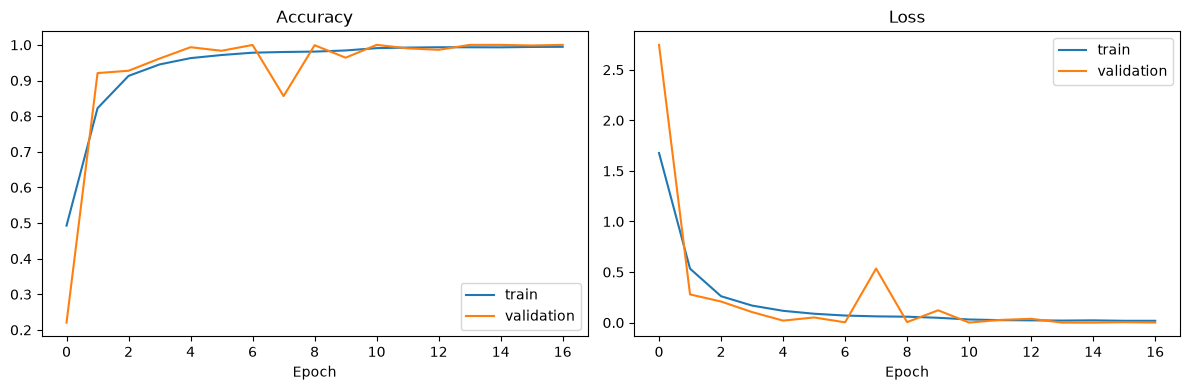

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m, title in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(history.history[m], label="train")
    ax.plot(history.history[f"val_{m}"], label="validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

In [8]:
proba = model.predict(X_test, verbose=0)
y_pred = proba.argmax(axis=1)

res_improved = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
}
print("CNN amélioré :", {k: round(v, 4) for k, v in res_improved.items()})
print()
print("Critères d'acceptation :")
print(f"  Accuracy >= 90 % : {'OK' if res_improved['accuracy'] >= 0.90 else 'NON ATTEINT'}")
print(f"  F1 macro >= 90 % : {'OK' if res_improved['f1_macro'] >= 0.90 else 'NON ATTEINT'}")

CNN amélioré : {'accuracy': 0.9944, 'precision_macro': 0.9969, 'recall_macro': 0.9932, 'f1_macro': 0.9947}

Critères d'acceptation :
  Accuracy >= 90 % : OK
  F1 macro >= 90 % : OK


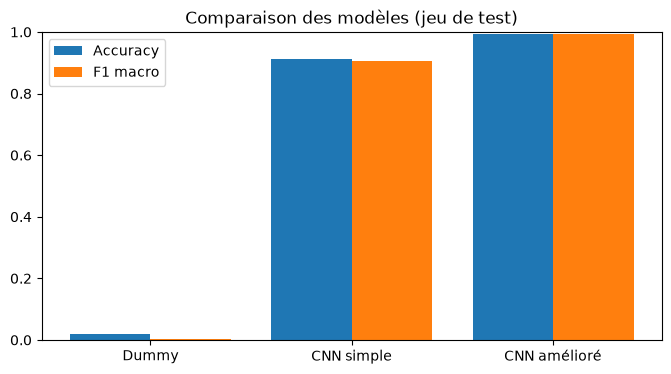

In [9]:
names = ["Dummy", "CNN simple", "CNN amélioré"]
accs = [baseline["dummy"]["accuracy"], baseline["cnn_simple"]["accuracy"], res_improved["accuracy"]]
f1s = [baseline["dummy"]["f1_macro"], baseline["cnn_simple"]["f1_macro"], res_improved["f1_macro"]]

x = np.arange(3)
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, accs, 0.4, label="Accuracy")
plt.bar(x + 0.2, f1s, 0.4, label="F1 macro")
plt.xticks(x, names); plt.ylim(0, 1); plt.legend()
plt.title("Comparaison des modèles (jeu de test)")
plt.show()

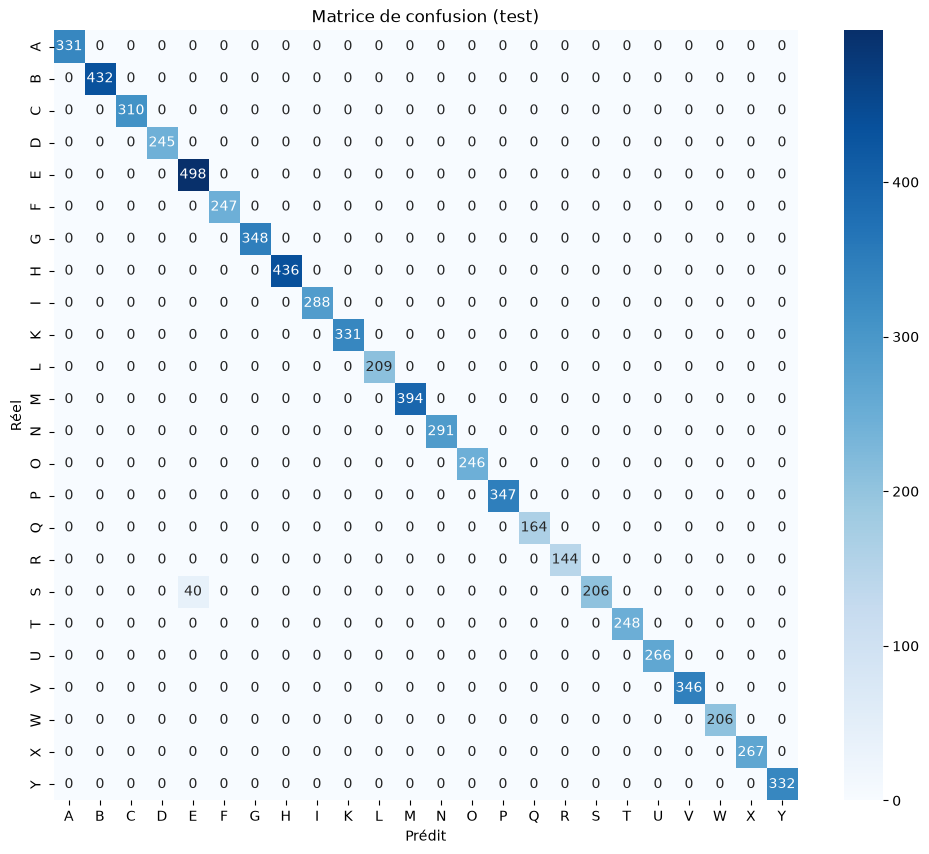

Confusions les plus fréquentes (réel -> prédit : nombre)
  S -> E : 40

              precision    recall  f1-score   support

           A      1.000     1.000     1.000       331
           B      1.000     1.000     1.000       432
           C      1.000     1.000     1.000       310
           D      1.000     1.000     1.000       245
           E      0.926     1.000     0.961       498
           F      1.000     1.000     1.000       247
           G      1.000     1.000     1.000       348
           H      1.000     1.000     1.000       436
           I      1.000     1.000     1.000       288
           K      1.000     1.000     1.000       331
           L      1.000     1.000     1.000       209
           M      1.000     1.000     1.000       394
           N      1.000     1.000     1.000       291
           O      1.000     1.000     1.000       246
           P      1.000     1.000     1.000       347
           Q      1.000     1.000     1.000       164
         

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=letters, yticklabels=letters)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title("Matrice de confusion (test)")
plt.show()

# Top des confusions
errors = [(letters[i], letters[j], cm[i, j])
          for i in range(24) for j in range(24) if i != j and cm[i, j] > 0]
errors.sort(key=lambda t: -t[2])
print("Confusions les plus fréquentes (réel -> prédit : nombre)")
for real, pred, n in errors[:10]:
    print(f"  {real} -> {pred} : {n}")

print()
print(classification_report(y_test, y_pred, target_names=letters, digits=3))

40 erreurs sur 7172


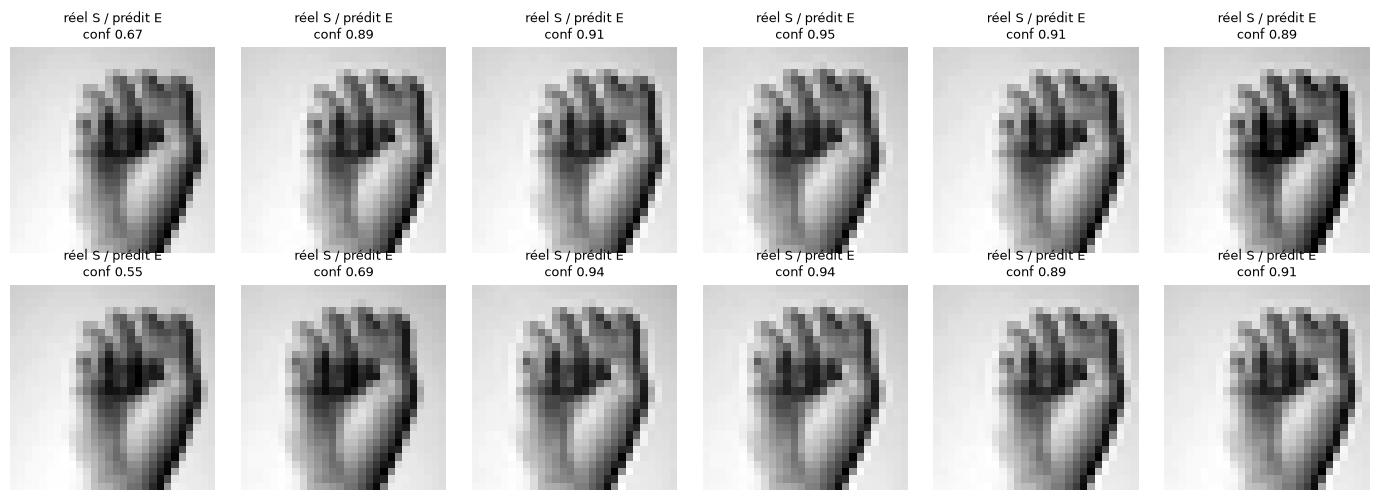

In [11]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} erreurs sur {len(y_test)}")

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), wrong[:12]):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"réel {letters[y_test[i]]} / prédit {letters[y_pred[i]]}\nconf {proba[i].max():.2f}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
one = X_test[:1]
model.predict(one, verbose=0)
t0 = time.time()
for _ in range(50):
    model.predict(one, verbose=0)
res_improved["ms_per_image"] = (time.time() - t0) / 50 * 1000
print(f"Temps moyen par image : {res_improved['ms_per_image']:.1f} ms")

model.save("../data/cnn_final.keras")

baseline["cnn_ameliore"] = {k: float(v) for k, v in res_improved.items()}
with open("../docs/results.json", "w") as f:
    json.dump(baseline, f, indent=2)

Temps moyen par image : 145.8 ms
